**CS 4140 – Deep Learning · L01 · Course launch: what machines learn** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L01_course-launch/L01_what_machines_learn.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L01_course-launch"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 1 · What does a deep network learn?

In Machine Learning you saw that a learning algorithm receives **vectors** and learns a **function** (the hypothesis).
For the Iris flowers the vector had 4 numbers that a botanist chose and measured, and a single line separated two species with 94% accuracy.

Deep learning keeps the same idea and changes one thing: **the network also learns which numbers to look at.**
In this notebook a network receives the raw 784 pixels of a handwritten digit and is forced to squeeze everything into **just 2 numbers**
before it decides. Then we can draw the space it invented.

| Section | What happens | Time |
|---|---|---|
| 1 | A digit is a vector of 784 numbers | instant (first run downloads MNIST, ~10 MB) |
| 2 | Classic recipe: compress the pixels to 2 numbers with PCA, then draw lines | ~3 s |
| 3 | Deep recipe: a network learns its own 2 numbers | ~30 s, or load saved weights |
| 4 | Watch the space form during training | instant |
| 5 | Things to try | — |

Set `RUN_TRAINING = False` in class to load `mnist_two_numbers.pt` instead of training.

In [1]:
import time, json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import ListedColormap
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

RUN_TRAINING = True        # False: load mnist_two_numbers.pt (saved by this notebook)
torch.manual_seed(0)
torch.set_num_threads(1)   # small model: one thread is fast enough and makes runs repeatable
FIG = Path('figs'); FIG.mkdir(exist_ok=True)

for fam in ['Century Schoolbook', 'TeX Gyre Schola', 'C059', 'DejaVu Serif']:
    if any(fam == f.name for f in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = fam
        break
plt.rcParams.update({'font.size': 16, 'axes.spines.top': False, 'axes.spines.right': False})
NAVY, RED, GREY = '#000080', '#E00000', '#808080'
DIGIT_COLORS = plt.cm.tab10(np.arange(10))
REGION_CMAP = ListedColormap(0.38 * DIGIT_COLORS[:, :3] + 0.62)   # pale versions of the same colours

train_set = datasets.MNIST('data', train=True, download=True)
test_set = datasets.MNIST('data', train=False, download=True)
X_train = train_set.data.float().div(255).view(-1, 784)   # 60,000 vectors of 784 numbers in [0, 1]
y_train = train_set.targets
X_test = test_set.data.float().div(255).view(-1, 784)     # 10,000 vectors the model never trains on
y_test = test_set.targets
print(X_train.shape, X_test.shape)

torch.Size([60000, 784]) torch.Size([10000, 784])


## 1. A digit is a vector of 784 numbers

"It is very hard to say what makes a 2." The algorithm does not see a 2: it sees 28 × 28 = 784 brightness values.

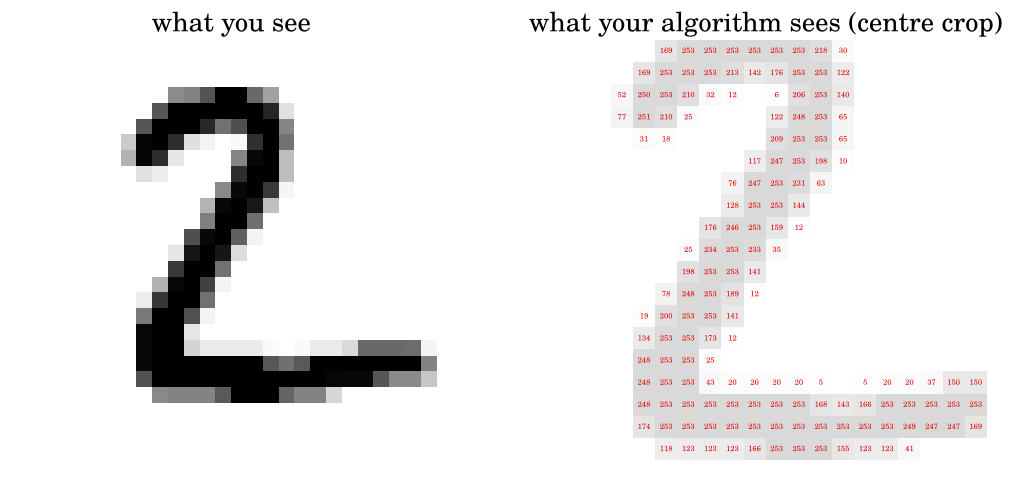

as one vector: torch.Size([784]) -> [0.   0.   0.   0.3  0.98 0.82 0.1  0.   0.   0.   0.48 0.97] ...


In [2]:
idx = int((y_test == 2).nonzero()[0])
img = X_test[idx].view(28, 28)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})
axes[0].imshow(img, cmap='gray_r'); axes[0].set_title('what you see'); axes[0].axis('off')
crop = img[4:24, 4:24]
axes[1].imshow(crop, cmap='gray_r', alpha=0.15)
for i in range(crop.shape[0]):
    for j in range(crop.shape[1]):
        v = int(round(255 * crop[i, j].item()))
        if v:
            axes[1].text(j, i, v, ha='center', va='center', fontsize=5.5, color=RED)
axes[1].set_title('what your algorithm sees (centre crop)'); axes[1].axis('off')
plt.tight_layout(); plt.show()
print('as one vector:', X_test[idx].shape, '->', X_test[idx][200:212].numpy().round(2), '...')

## 2. The classic recipe: we choose the 2 numbers, then the algorithm draws lines

We need 2 numbers per image to draw anything. PCA (principal component analysis, from your ML course) gives the 2 directions in which the 784 pixels vary most.
A linear classifier (softmax regression) then draws straight boundaries between the digits, exactly like the Iris line.

In [3]:
def pca_2d(X, X_new):
    mean = X.mean(0)
    cov = (X - mean).T @ (X - mean) / len(X)
    _, vecs = torch.linalg.eigh(cov)              # eigenvalues in ascending order
    V = vecs[:, [-1, -2]]                         # the 2 directions of largest variance
    return (X - mean) @ V, (X_new - mean) @ V

def train_linear(Z, y, Z_test, y_test, standardize=True, iters=100):
    # softmax regression = one linear layer + cross-entropy, fitted with full-batch L-BFGS
    torch.manual_seed(0)
    mu = Z.mean(0) if standardize else torch.zeros(Z.shape[1])
    sd = Z.std(0) if standardize else torch.ones(Z.shape[1])
    Zs = (Z - mu) / sd
    clf = nn.Linear(Z.shape[1], 10)
    opt = torch.optim.LBFGS(clf.parameters(), lr=1, max_iter=iters, history_size=20, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad()
        loss = nn.functional.cross_entropy(clf(Zs), y) + 1e-4 * clf.weight.pow(2).sum()
        loss.backward()
        return loss
    opt.step(closure)
    with torch.no_grad():
        acc = (clf((Z_test - mu) / sd).argmax(1) == y_test).float().mean().item()
    return clf, mu, sd, acc

t0 = time.time()
P_train, P_test = pca_2d(X_train, X_test)
pca_clf, pca_mu, pca_sd, pca_acc = train_linear(P_train, y_train, P_test, y_test)
if RUN_TRAINING or not Path('results.json').exists():
    _, _, _, raw_acc = train_linear(X_train, y_train, X_test, y_test, standardize=False)   # ~10 s
else:
    raw_acc = json.load(open('results.json'))['raw_784_linear']                          # saved by a full run
print(f'2 numbers from PCA + straight lines:   {pca_acc:.1%}')
print(f'all 784 pixels + straight boundaries:  {raw_acc:.1%}   ({time.time() - t0:.0f} s)')

2 numbers from PCA + straight lines:   44.6%
all 784 pixels + straight boundaries:  92.5%   (12 s)


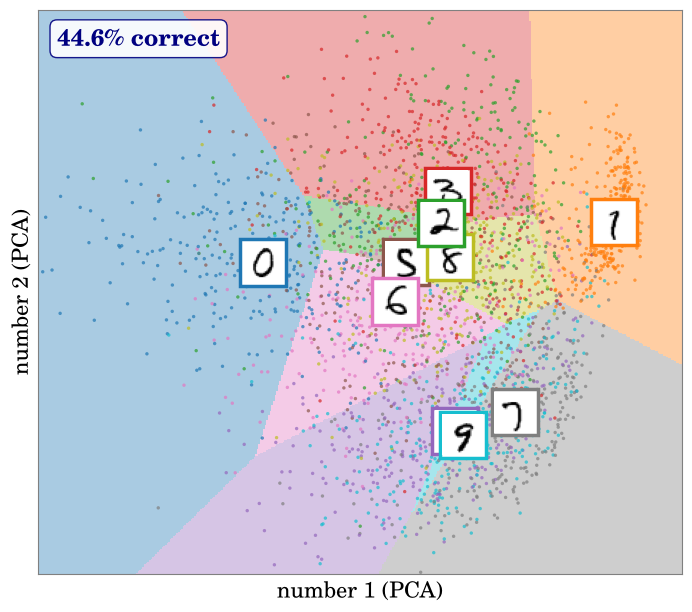

In [4]:
def draw_space(ax, Z, y, decide, n_points=3000, thumbs=True, title=None, acc=None, pad=0.08):
    Z = Z[:n_points].numpy(); y = y[:n_points].numpy()
    lo, hi = np.percentile(Z, 0.5, axis=0), np.percentile(Z, 99.5, axis=0)
    span = hi - lo; lo, hi = lo - pad * span, hi + pad * span
    gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 400), np.linspace(lo[1], hi[1], 400))
    grid = torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        region = decide(grid).argmax(1).numpy().reshape(gx.shape)
    ax.imshow(region, origin='lower', extent=(lo[0], hi[0], lo[1], hi[1]), cmap=REGION_CMAP, vmin=-0.5, vmax=9.5,
              aspect='auto', interpolation='nearest')
    ax.scatter(Z[:, 0], Z[:, 1], c=DIGIT_COLORS[y], s=6, alpha=0.7, linewidths=0)
    if thumbs:
        for d in [0, 1, 3, 4, 5, 6, 7, 8, 9, 2]:          # the 2 last, so it is drawn on top
            members = np.where(y == d)[0]
            centre = np.median(Z[members], axis=0)
            k = members[np.argmin(((Z[members] - centre) ** 2).sum(1))]     # the most typical example
            box = OffsetImage(X_test[k].view(28, 28).numpy(), cmap='gray_r', zoom=1.05)
            ab = AnnotationBbox(box, Z[k], frameon=True, pad=0.12,
                                bboxprops=dict(edgecolor=DIGIT_COLORS[d], linewidth=2.5))
            ax.add_artist(ab)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(GREY)
    if title:
        ax.set_title(title, fontsize=17)
    if acc is not None:
        ax.text(0.03, 0.97, f'{acc:.1%} correct', transform=ax.transAxes, ha='left', va='top', fontsize=17, color=NAVY,
                fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=NAVY, alpha=0.9))

pca_decide = lambda g: pca_clf((g - pca_mu) / pca_sd)
fig, ax = plt.subplots(figsize=(7.2, 6.4))
draw_space(ax, P_test, y_test, pca_decide, acc=pca_acc)
ax.set_xlabel('number 1 (PCA)'); ax.set_ylabel('number 2 (PCA)')
plt.tight_layout(); fig.savefig(FIG / 'pca_space.png', dpi=200, bbox_inches='tight'); plt.show()

**What to notice.** The digits pile on top of each other: two numbers chosen *without knowing the task* throw away what matters, and straight lines get only about 45% right.
(With all 784 pixels a linear classifier gets about 92%: the information is there, a single layer of lines just cannot organise it into 2 numbers.)

## 3. The deep recipe: the network learns its own 2 numbers

The network below has a **bottleneck**: three layers turn 784 pixels into 2 numbers, and one final linear layer (straight lines again) decides the digit from those 2 numbers.
Nobody tells it what the 2 numbers should mean. Training adjusts all 533,792 weights together (backpropagation, from your ML course) so that the final lines work.

In [5]:
class TwoNumberNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(            # learned: 784 pixels -> 2 numbers
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 2))
        self.classifier = nn.Linear(2, 10)         # straight lines in the learned 2-D space

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(0)
model = TwoNumberNet()
print(sum(p.numel() for p in model.parameters()), 'parameters')

SNAP_STEPS = [0, 50, 469, 4690]                   # before training, 50 steps, 1 epoch, 10 epochs
snap_x = X_test[:3000]

def snapshot(m):
    m.eval()
    with torch.no_grad():
        z = m.features(snap_x)
        acc = (m(X_test).argmax(1) == y_test).float().mean().item()
    m.train()
    return z, acc, {k: v.clone() for k, v in m.classifier.state_dict().items()}

if RUN_TRAINING:
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
    snaps, step, t0 = {0: snapshot(model)}, 0, time.time()
    for epoch in range(10):
        for x, y in loader:
            loss = nn.functional.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            step += 1
            if step in SNAP_STEPS:
                snaps[step] = snapshot(model)
        print(f'epoch {epoch + 1:2d}  test accuracy {snapshot(model)[1]:.1%}  ({time.time() - t0:.0f} s)')
    torch.save({'model': model.state_dict(), 'snaps': snaps}, 'mnist_two_numbers.pt')
else:
    saved = torch.load('mnist_two_numbers.pt', weights_only=False)
    model.load_state_dict(saved['model']); snaps = saved['snaps']
model.eval()
with torch.no_grad():
    Z_test = model.features(X_test)
    deep_acc = (model.classifier(Z_test).argmax(1) == y_test).float().mean().item()
print(f'2 numbers learned by the network + straight lines: {deep_acc:.1%}')

533792 parameters


epoch  1  test accuracy 91.2%  (3 s)


epoch  2  test accuracy 93.2%  (7 s)


epoch  3  test accuracy 94.0%  (11 s)


epoch  4  test accuracy 95.2%  (15 s)


...

epoch  6  test accuracy 96.3%  (22 s)


epoch  7  test accuracy 95.9%  (26 s)


epoch  8  test accuracy 96.3%  (31 s)


epoch  9  test accuracy 96.0%  (35 s)


epoch 10  test accuracy 96.4%  (39 s)
2 numbers learned by the network + straight lines: 96.4%


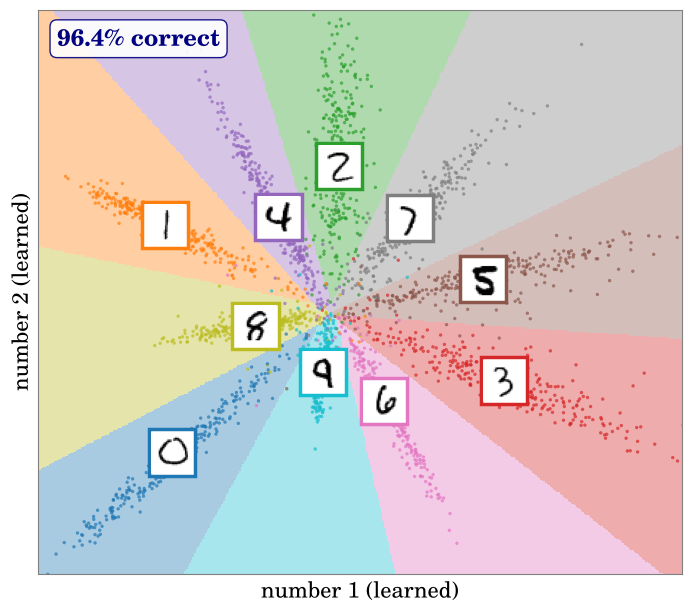

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 6.4))
draw_space(ax, Z_test, y_test, model.classifier, acc=deep_acc)
ax.set_xlabel('number 1 (learned)'); ax.set_ylabel('number 2 (learned)')
plt.tight_layout(); fig.savefig(FIG / 'learned_space.png', dpi=200, bbox_inches='tight'); plt.show()

**What to notice.** Same 2 numbers per image, same kind of straight lines at the end, but now about 96% correct.
The hidden layers built a new space in which each digit has its own region: the network learned **what makes a 2** without anyone describing it.
That is representation learning, the core idea of this course. The coloured regions are the decision surface of the hypothesis function, as in the kNN example of your ML course.

## 4. Watch the space form during training

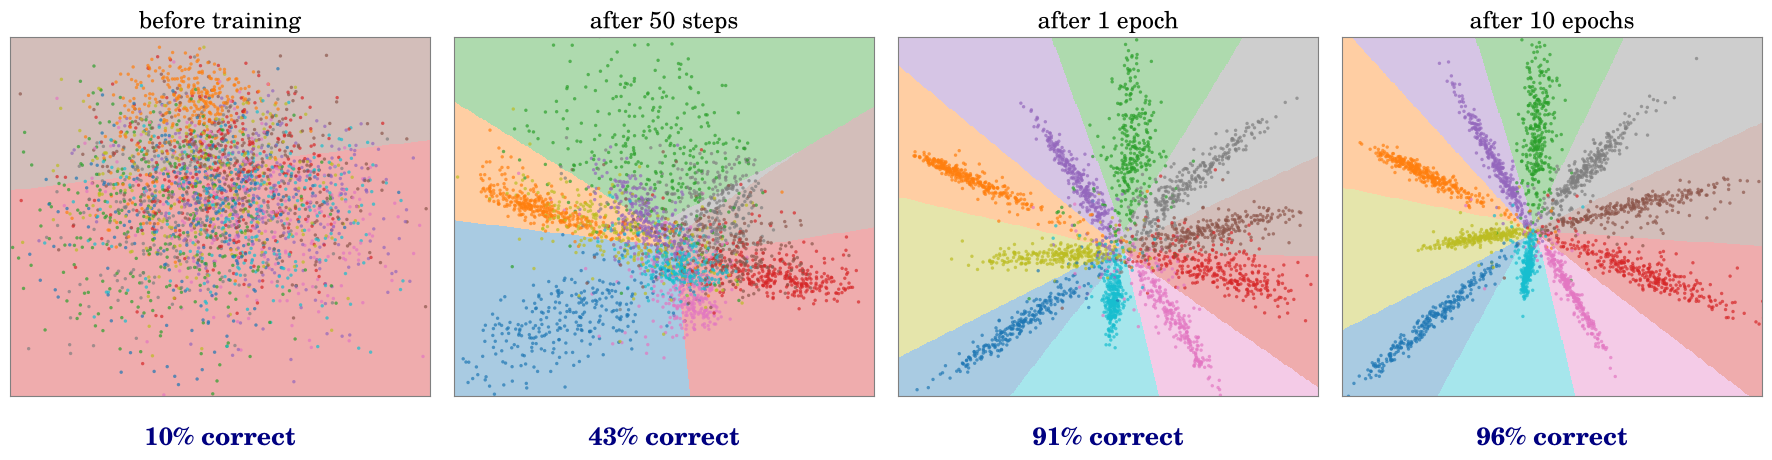

{'pca_2_numbers_linear': 0.4464,
 'raw_784_linear': 0.9255,
 'learned_2_numbers_linear': 0.9641,
 'parameters': 533792,
 'snapshot_accuracy': {'0': 0.1003,
  '50': 0.4272,
  '469': 0.9119,
  '4690': 0.9641}}

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.9))
labels = {0: 'before training', 50: 'after 50 steps', 469: 'after 1 epoch', 4690: 'after 10 epochs'}
for ax, s in zip(axes, SNAP_STEPS):
    z, acc, clf_state = snaps[s]
    head = nn.Linear(2, 10); head.load_state_dict(clf_state)
    draw_space(ax, z, y_test[:3000], head, thumbs=False, title=labels[s])
    ax.text(0.5, -0.08, f'{acc:.0%} correct', transform=ax.transAxes, ha='center', va='top', fontsize=18, color=NAVY, fontweight='bold')
plt.tight_layout(); fig.savefig(FIG / 'learning_snapshots.png', dpi=200, bbox_inches='tight'); plt.show()

results = {'pca_2_numbers_linear': round(pca_acc, 4), 'raw_784_linear': round(raw_acc, 4),
           'learned_2_numbers_linear': round(deep_acc, 4), 'parameters': sum(p.numel() for p in model.parameters()),
           'snapshot_accuracy': {str(s): round(snaps[s][1], 4) for s in SNAP_STEPS}}
json.dump(results, open('results.json', 'w'), indent=1)
results

**What to notice.** Before training the 2 numbers are random mixtures of pixels and the lines are random: about 10% correct, pure guessing.
Within one epoch the digits have already pulled apart. Learning the function and learning the representation are the same process.

## 5. Things to try (after class)

1. **Find the confusions.** Which pairs of digit regions touch? Plot a few test images that sit near a boundary. Would you have got them right?
2. **More numbers.** Change the bottleneck to 3 or 10 numbers. How much does accuracy improve? Why can we no longer draw the space?
3. **Shallow versus deep.** Remove the two hidden layers (`nn.Linear(784, 2)` straight to the classifier). What happens to the space and the accuracy? (Lecture 4, Jan 18, is about exactly this.)
4. **Use your AI, then verify.** Ask an AI assistant to make this network reach 99%. Run its suggestion yourself: did it work, and do you understand why?